# 03 · Pertanyaan bisnis 2–5 dan cek ketepatan

> **DATA DUMMY.** Seluruh angka di notebook ini berasal dari `data/dummy/*_dummy.csv` buatan
> `data/dummy/generate_orders.py` (seed 42), bukan pesanan asli. Data dipotong 15 Nov 2026 20.00 WIB.

Pertanyaan dari `docs/business_questions.md`; rumus dari data dictionary v1.3 bagian 18 dan
`docs/data_limitation_log.md`. Q1 dan omzet ada di notebook 02.

Setiap pertanyaan ditutup bagian **Cek ketepatan**: angka dihitung ulang lewat jalur lain dan
dibandingkan dengan `assert`. Kalau ada yang tidak cocok, notebook berhenti di sel itu.

Aturan umum: tabel anak (`order_item_options`, `payments`, `deliveries`) diagregasi per tabel dulu
sebelum di-join, supaya tidak terjadi hitung ganda.

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path("../data/dummy")
NOW = pd.Timestamp("2026-11-15 20:00", tz="Asia/Jakarta")  # batas data dummy, sama dengan generate_orders.py
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

orders = pd.read_csv(DATA / "orders_dummy.csv", parse_dates=["invoice_sent_at", "created_at"])
deliveries = pd.read_csv(DATA / "deliveries_dummy.csv", parse_dates=["delivery_date"])
items = pd.read_csv(DATA / "order_items_dummy.csv")
item_opts = pd.read_csv(DATA / "order_item_options_dummy.csv")
menus = pd.read_csv(DATA / "menus_dummy.csv")
menu_opts = pd.read_csv(DATA / "menu_options_dummy.csv")
events = pd.read_csv(DATA / "order_events_dummy.csv", parse_dates=["created_at"])
payments = pd.read_csv(DATA / "payments_dummy.csv", parse_dates=["paid_at"])

# Pesanan yang dimasak / dihitung omzet (D01): diproses atau selesai
aktif_ids = orders.loc[orders["status"].isin(["diproses", "selesai"]), "id"]
{n: len(df) for n, df in [("orders", orders), ("deliveries", deliveries), ("order_items", items),
                          ("order_item_options", item_opts), ("order_events", events), ("payments", payments)]}

{'orders': 180,
 'deliveries': 199,
 'order_items': 413,
 'order_item_options': 663,
 'order_events': 992,
 'payments': 183}

## Q2. Berapa porsi per tanggal masak, dan hari apa paling padat?

- **Tanggal masak = `deliveries.delivery_date`** (A07).
- **Porsi** (D03, D05): 1 pcs menu = 1 porsi; bonus Rp0 dihitung porsi; bundling dihitung 1 porsi per paket
  (di aplikasi disimpan satu baris tanpa komponen); `kolaborasi` (minuman) **tidak** dihitung.
- Hanya pesanan **diproses** atau **selesai**. Pesanan dibatalkan tidak dimasak; pesanan menunggu belum pasti.
- Rata-rata per hari dalam seminggu memakai **semua tanggal kalender** di rentang data (hari tanpa kiriman = 0 porsi),
  supaya hari yang jarang ada pesanan tidak terlihat padat.

In [2]:
porsi_item = items[items["order_id"].isin(aktif_ids) & (items["item_type"] != "kolaborasi")]
porsi_item = porsi_item.merge(deliveries[["id", "delivery_date"]], left_on="delivery_id",
                              right_on="id", suffixes=("", "_kirim"))

porsi_harian = (porsi_item.groupby("delivery_date")["qty"].sum()
                .reindex(pd.date_range(porsi_item["delivery_date"].min(), porsi_item["delivery_date"].max()),
                         fill_value=0)
                .rename_axis("tanggal_masak").rename("porsi").reset_index())
porsi_harian["hari"] = porsi_harian["tanggal_masak"].dt.day_of_week.map(dict(enumerate(HARI)))
porsi_harian.sort_values("porsi", ascending=False).head(5)

,tanggal_masak,porsi,hari
46,2026-10-18,31,Minggu
57,2026-10-29,29,Kamis
48,2026-10-20,29,Selasa
53,2026-10-25,28,Minggu
43,2026-10-15,28,Kamis


In [3]:
per_hari = (porsi_harian.groupby("hari")["porsi"]
            .agg(rata_rata="mean", total="sum", jumlah_tanggal="count", maks="max")
            .reindex(HARI))
per_hari.round(1)

,rata_rata,total,jumlah_tanggal,maks
hari,,,,
Senin,10.2,112,11,26
Selasa,9.5,104,11,29
Rabu,11.2,134,12,27
Kamis,15.2,183,12,29
Jumat,9.7,116,12,22
Sabtu,7.9,95,12,20
Minggu,9.9,119,12,31


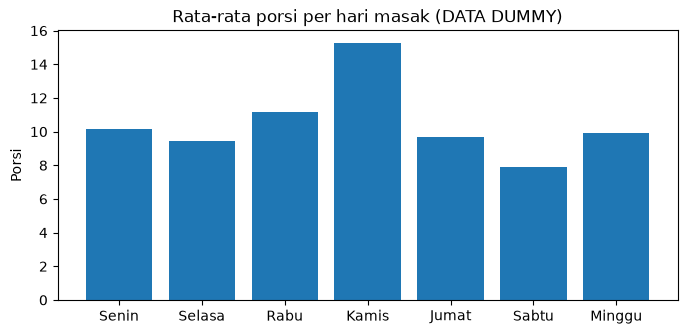

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(per_hari.index, per_hari["rata_rata"])
ax.set_title("Rata-rata porsi per hari masak (DATA DUMMY)")
ax.set_ylabel("Porsi");

In [5]:
puncak = porsi_harian.loc[porsi_harian["porsi"].idxmax()]
print(f"Tanggal terpadat: {puncak['tanggal_masak']:%d %b %Y} ({puncak['hari']}), {puncak['porsi']} porsi")
print(f"Hari rata-rata terpadat: {per_hari['rata_rata'].idxmax()} ({per_hari['rata_rata'].max():.1f} porsi)")
print(f"Rata-rata harian: {porsi_harian['porsi'].mean():.1f} porsi, {(porsi_harian['porsi'] == 0).sum()} hari tanpa masak")

Tanggal terpadat: 18 Oct 2026 (Minggu), 31 porsi
Hari rata-rata terpadat: Kamis (15.2 porsi)
Rata-rata harian: 10.5 porsi, 8 hari tanpa masak


### Cek ketepatan Q2

1. Total porsi harian = Σ `qty` langsung dari item (tanpa join ke pengiriman).
2. Join ke pengiriman tidak menambah atau mengurangi baris item.
3. Total per jenis item cocok; `kolaborasi` tidak ikut, `bonus` ikut.
4. Rata-rata per hari × jumlah tanggal = total.

In [6]:
langsung = items.loc[items["order_id"].isin(aktif_ids) & (items["item_type"] != "kolaborasi"), "qty"]
assert len(porsi_item) == len(langsung), "join ke deliveries tidak boleh mengubah jumlah baris"
assert porsi_harian["porsi"].sum() == langsung.sum() == per_hari["total"].sum()

per_jenis = porsi_item.groupby("item_type")["qty"].sum()
assert "kolaborasi" not in per_jenis.index and per_jenis.sum() == langsung.sum()
assert ((per_hari["rata_rata"] * per_hari["jumlah_tanggal"]).round() == per_hari["total"]).all()
assert len(porsi_harian) == porsi_harian["tanggal_masak"].nunique(), "satu baris per tanggal"
print(f"OK. Total porsi {langsung.sum()}; per jenis: {per_jenis.to_dict()}")

OK. Total porsi 863; per jenis: {'bonus': 26, 'bundling': 16, 'item_bebas': 9, 'menu': 812}


## Q3. Berapa pesanan diundur, dibatalkan, atau lewat batas bayar, dan apa alasannya?

- **Diundur** = pesanan dengan event `rescheduled`; alasan dari `order_events.reason`.
- **Dibatalkan** = `orders.status = 'dibatalkan'` (bukan jumlah event, data dictionary bagian 18); alasan dari event `cancelled`.
- **Lewat batas bayar** (D04, KF 6): hanya `pay_timing = 'di_muka'`; batas = `invoice_sent_at` + 4 jam.
  Dihitung **pernah lewat batas**: pembayaran pertama sesudah batas, atau belum dibayar sama sekali ketika batas lewat
  (pesanan yang dibatalkan sebelum batasnya lewat tidak dihitung).
  Lewat batas hanya tanda, bukan batal otomatis.
- Penyebut persentase: semua pesanan (diundur, dibatalkan) dan pesanan bayar di muka yang tagihannya sudah dikirim (lewat batas).

In [7]:
n_order = len(orders)
resch = events[events["event_type"] == "rescheduled"]
batal = orders[orders["status"] == "dibatalkan"].merge(
    events.loc[events["event_type"] == "cancelled", ["order_id", "reason"]],
    left_on="id", right_on="order_id", how="left")

alasan_undur = resch["reason"].value_counts().rename("pesanan")
alasan_batal = batal["reason"].value_counts().rename("pesanan")
print(f"Diundur: {resch['order_id'].nunique()} dari {n_order} pesanan ({resch['order_id'].nunique() / n_order:.1%})")
print(alasan_undur.to_string(), "\n")
print(f"Dibatalkan: {len(batal)} dari {n_order} pesanan ({len(batal) / n_order:.1%})")
print(alasan_batal.to_string())

Diundur: 9 dari 180 pesanan (5.0%)
reason
Jadwal masak bentrok (dummy)    6
Bahan belum tersedia (dummy)    3 

Dibatalkan: 27 dari 180 pesanan (15.0%)
reason
Lewat batas bayar (dummy)                 9
Pelanggan minta batal (dummy)             7
Pelanggan minta refund (dummy)            6
Pelanggan menolak jadwal ulang (dummy)    3
Tanggal kirim penuh (dummy)               2


In [8]:
bayar_pertama = (payments[payments["type"] != "refund"]
                 .groupby("order_id")["paid_at"].min().rename("bayar_pertama"))
waktu_batal = events[events["event_type"] == "cancelled"].groupby("order_id")["created_at"].min().rename("waktu_batal")
tagih = orders[(orders["pay_timing"] == "di_muka") & orders["invoice_sent_at"].notna()] \
    .join(bayar_pertama, on="id").join(waktu_batal, on="id")
tagih["batas_bayar"] = tagih["invoice_sent_at"] + pd.Timedelta(hours=4)
# Belum dibayar dihitung lewat batas hanya jika batasnya lewat sebelum NOW dan sebelum pesanan dibatalkan
berhenti = tagih["waktu_batal"].where(tagih["waktu_batal"].notna(), NOW).clip(upper=NOW)
tagih["lewat_batas"] = (tagih["bayar_pertama"] > tagih["batas_bayar"]) | \
                       (tagih["bayar_pertama"].isna() & (tagih["batas_bayar"] < berhenti))
tagih["kategori"] = "tepat waktu / batas belum lewat"
tagih.loc[tagih["lewat_batas"] & tagih["bayar_pertama"].notna(), "kategori"] = "lewat batas, tetap dibayar"
tagih.loc[tagih["lewat_batas"] & tagih["bayar_pertama"].isna(), "kategori"] = "lewat batas, tidak dibayar"

lewat = tagih[tagih["lewat_batas"]]
print(f"Lewat batas bayar: {len(lewat)} dari {len(tagih)} pesanan bayar di muka yang ditagih ({len(lewat) / len(tagih):.1%})")
pd.crosstab(tagih["kategori"], tagih["status"], margins=True, margins_name="total")

Lewat batas bayar: 14 dari 129 pesanan bayar di muka yang ditagih (10.9%)


status,dibatalkan,diproses,selesai,total
kategori,,,,
"lewat batas, tetap dibayar",0,1,4,5
"lewat batas, tidak dibayar",9,0,0,9
tepat waktu / batas belum lewat,11,9,95,115
total,20,10,99,129


### Cek ketepatan Q3

1. Satu pembatalan = satu event `cancelled`; semua pesanan batal punya alasan.
2. Setiap jadwal ulang memundurkan tanggal (`new_date` > `old_date`) dan punya alasan.
3. Pesanan "lewat batas, tidak dibayar" yang dibatalkan = tepat pesanan yang dibatalkan dengan alasan "Lewat batas bayar".
4. Tidak ada pesanan `setelah_kirim` di hitungan lewat batas.
5. Rumus "Lewat batas bayar" di data dictionary bagian 18 (`pembayaran bersih = 0` saat ini) ikut dihitung sebagai pembanding.

In [9]:
assert len(batal) == (events["event_type"] == "cancelled").sum() and batal["reason"].notna().all()
assert (pd.to_datetime(resch["new_date"]) > pd.to_datetime(resch["old_date"])).all() and resch["reason"].notna().all()
batal_lewat = batal.loc[batal["reason"].str.startswith("Lewat batas bayar"), "id"]
tdk_bayar_batal = lewat.loc[lewat["bayar_pertama"].isna() & (lewat["status"] == "dibatalkan"), "id"]
assert set(batal_lewat) == set(tdk_bayar_batal)
assert (tagih["pay_timing"] == "di_muka").all()

# Rumus bagian 18: di_muka, batas < now, pembayaran bersih = 0
bersih = payments.assign(net=payments["amount"].where(payments["type"] != "refund", -payments["amount"])) \
                 .groupby("order_id")["net"].sum()
rumus18 = tagih[(tagih["batas_bayar"] < NOW) & (tagih["id"].map(bersih).fillna(0) == 0)]
print("Rumus bagian 18 menandai", len(rumus18), "pesanan, status:", rumus18["status"].value_counts().to_dict())
print("  di antaranya tidak pernah lewat batas (batal sebelum batas, atau sudah bayar lalu di-refund):",
      (rumus18["status"].eq("dibatalkan") & ~rumus18["lewat_batas"]).sum())

Rumus bagian 18 menandai 19 pesanan, status: {'dibatalkan': 19}
  di antaranya tidak pernah lewat batas (batal sebelum batas, atau sudah bayar lalu di-refund): 10


**Temuan:** rumus bagian 18 ikut menandai pesanan yang sudah **dibatalkan** (pembayaran bersih 0), termasuk yang
batal sebelum batasnya lewat dan yang sudah di-refund. Untuk tanda di aplikasi, rumusnya perlu ditambah
`status = 'menunggu_pembayaran'`. Usulan ini perlu dikonfirmasi DS 2 / Full-Stack.

## Q4. Berapa tagihan yang sudah dikirim tetapi belum dibayar?

- **Tagihan terbuka** = `invoice_sent_at` terisi, pesanan tidak dibatalkan, dan status bayar Belum Bayar atau DP.
- **Total pesanan** = Σ total item + Σ ongkir − diskon; **sisa tagihan** = total pesanan − pembayaran bersih (bagian 18).
- **Umur tagihan** = `NOW` − `invoice_sent_at`.

In [10]:
opsi_per_item = item_opts.groupby("order_item_id")["extra_price"].sum()
total_item = (items["qty"] * (items["unit_price"] + items["id"].map(opsi_per_item).fillna(0))).groupby(items["order_id"]).sum()
ongkir = deliveries.groupby("order_id")["shipping_fee"].sum()

o = orders.set_index("id")
o["total_pesanan"] = total_item.reindex(o.index, fill_value=0) + ongkir.reindex(o.index, fill_value=0) - o["discount"]
o["bayar_bersih"] = bersih.reindex(o.index, fill_value=0)
o["sisa"] = o["total_pesanan"] - o["bayar_bersih"]

terbuka = o[o["invoice_sent_at"].notna() & (o["status"] != "dibatalkan") & o["pay_status"].isin(["belum_bayar", "dp"])].copy()
terbuka["umur_hari"] = (NOW - terbuka["invoice_sent_at"]).dt.total_seconds() / 86400
terbuka["umur"] = pd.cut(terbuka["umur_hari"], [0, 1, 3, 7, float("inf")],
                         labels=["< 1 hari", "1–3 hari", "3–7 hari", "> 7 hari"])

rp = lambda v: f"Rp{v:,.0f}".replace(",", ".")
print(f"Tagihan terbuka: {len(terbuka)} pesanan, sisa {rp(terbuka['sisa'].sum())}")
terbuka.groupby(["pay_status", "pay_timing"]).agg(pesanan=("sisa", "size"), sisa=("sisa", "sum"))

Tagihan terbuka: 12 pesanan, sisa Rp2.052.000


,,pesanan,sisa
pay_status,pay_timing,,
belum_bayar,setelah_kirim,8,1832000.0
dp,di_muka,4,220000.0


In [11]:
terbuka.groupby("umur", observed=False).agg(pesanan=("sisa", "size"), sisa=("sisa", "sum"))

,pesanan,sisa
umur,,
< 1 hari,2,83000.0
1–3 hari,4,889000.0
3–7 hari,1,697000.0
> 7 hari,5,383000.0


### Cek ketepatan Q4

1. `orders.pay_status` sama dengan status yang dihitung ulang dari `payments` dan total pesanan.
2. Semua tagihan terbuka punya sisa > 0; pesanan Lunas sisanya tepat 0.
3. Σ sisa = Σ total pesanan − Σ pembayaran bersih pada tagihan terbuka.
4. Join opsi per item tidak menggandakan item.

In [12]:
hitung_ulang = pd.Series("dp", index=o.index)
hitung_ulang[o["bayar_bersih"] >= o["total_pesanan"]] = "lunas"
hitung_ulang[o["bayar_bersih"] == 0] = "belum_bayar"
refund_ids = payments.loc[payments["type"] == "refund", "order_id"].unique()
hitung_ulang[o.index.isin(refund_ids)] = "dikembalikan"
assert (hitung_ulang == o["pay_status"]).all(), o[hitung_ulang != o["pay_status"]]

assert (terbuka["sisa"] > 0).all()
assert (o.loc[o["pay_status"] == "lunas", "sisa"] == 0).all()
assert terbuka["sisa"].sum() == terbuka["total_pesanan"].sum() - terbuka["bayar_bersih"].sum()
assert total_item.sum() == (items["qty"] * items["unit_price"]).sum() + \
    item_opts.merge(items[["id", "qty"]], left_on="order_item_id", right_on="id").eval("qty * extra_price").sum()
print("OK")

OK


## Q5. Opsi kustom apa yang paling sering diminta?

- Hanya item `menu` dari pesanan **diproses** atau **selesai** (bahan yang benar-benar disiapkan).
- **Opsi kustom** = tambah keju, ayam dada/paha, tanpa makaroni, tanpa brokoli. Tingkat pedas wajib dipilih, jadi
  yang dilihat **sebarannya** (light/medium/spicy), bukan persentase pemakaiannya.
- Dihitung per baris item dan per porsi (`qty`), karena satu baris bisa berisi beberapa porsi dengan opsi yang sama.

In [13]:
menu_item = items[items["order_id"].isin(aktif_ids) & (items["item_type"] == "menu")] \
    .merge(menus[["id", "name"]].rename(columns={"id": "mid", "name": "menu"}), left_on="menu_id", right_on="mid")
opsi = item_opts.merge(menu_opts[["id", "menu_id", "option_group", "name"]].rename(columns={"menu_id": "menu_id_opsi"}),
                       left_on="menu_option_id", right_on="id") \
                .merge(menu_item[["id", "menu", "menu_id", "qty"]], left_on="order_item_id", right_on="id",
                       suffixes=("", "_item"))
kustom = opsi[opsi["option_group"] != "pedas"]

frek = (kustom.groupby(["menu", "name"]).agg(item=("order_item_id", "size"), porsi=("qty", "sum"))
        .join(menu_item.groupby("menu").size().rename("item_menu"), on="menu"))
frek["persen_item"] = (frek["item"] / frek["item_menu"] * 100).round(1)
frek.sort_values("porsi", ascending=False)

item  porsi  item_menu  persen_item
menu      name                                               
Wraphoria Ayam paha         40     98        105         38.1
          Ayam dada         31     75        105         29.5
Mackster  Tambah keju       23     56         90         25.6
Nutrimac  Ayam dada         20     52         72         27.8
          Ayam paha         21     52         72         29.2
Wraphoria Tambah keju       20     51        105         19.0
Mac Bites Ayam paha         21     47         50         42.0
          Ayam dada         16     44         50         32.0
Nutrimac  Tambah keju       15     39         72         20.8
Mac Bites Tambah keju       14     32         50         28.0
Nutrimac  Tanpa brokoli      9     20         72         12.5
          Tanpa makaroni     6     20         72          8.3

In [14]:
pakai = menu_item.assign(pakai_kustom=menu_item["id"].isin(kustom["order_item_id"])) \
                 .groupby("menu")["pakai_kustom"].mean().mul(100).round(1).rename("% item pakai opsi kustom")
pedas = pd.crosstab(opsi.loc[opsi["option_group"] == "pedas", "menu"],
                    opsi.loc[opsi["option_group"] == "pedas", "name"], normalize="index").mul(100).round(1)
pedas.join(pakai)

,Light,Medium,Spicy,% item pakai opsi kustom
menu,,,,
Mac Bites,36.0,32.0,32.0,82.0
Mackster,35.6,30.0,34.4,25.6
Nutrimac,34.7,33.3,31.9,72.2
Wraphoria,30.5,32.4,37.1,73.3


In [15]:
print("Opsi kustom terbanyak (porsi, semua menu):")
print(kustom.groupby("name")["qty"].sum().sort_values(ascending=False).to_string())

Opsi kustom terbanyak (porsi, semua menu):
name
Ayam paha         197
Tambah keju       178
Ayam dada         171
Tanpa brokoli      20
Tanpa makaroni     20


### Cek ketepatan Q5

1. Setiap opsi milik menu yang sama dengan itemnya, dan pasangan menu–opsi sesuai KF 7.
2. Setiap item menu punya tepat satu tingkat pedas; item non-menu tidak punya opsi.
3. Persentase ≤ 100% dan sebaran pedas per menu berjumlah 100%.

In [16]:
KF7 = {"Mackster": {"pedas", "keju"},
       "Nutrimac": {"pedas", "keju", "tanpa_makaroni", "tanpa_brokoli", "ayam"},
       "Wraphoria": {"pedas", "keju", "ayam"},
       "Mac Bites": {"pedas", "keju", "ayam"}}
assert (opsi["menu_id_opsi"] == opsi["menu_id"]).all(), "opsi tidak boleh nyasar ke menu lain"
assert all(g in KF7[m] for m, g in opsi[["menu", "option_group"]].itertuples(index=False))
jml_pedas = opsi[opsi["option_group"] == "pedas"].groupby("order_item_id").size()
assert len(jml_pedas) == len(menu_item) and (jml_pedas == 1).all(), "tepat satu tingkat pedas per item menu"
assert not item_opts["order_item_id"].isin(items.loc[items["item_type"] != "menu", "id"]).any()
assert (frek["persen_item"] <= 100).all() and (pakai <= 100).all()
assert (pedas.sum(axis=1).round() == 100).all()
print("OK")

OK


## Ringkasan

Jawaban per pertanyaan dicetak di sel masing-masing. Semua cek ketepatan lolos jika notebook berjalan sampai sini.

**Keterbatasan:** semua angka dari data dummy dengan peluang yang ditulis di `generate_orders.py`
(misalnya 10% jadwal ulang, 6% lewat batas lalu batal), jadi angkanya hanya membuktikan alur dan rumus,
bukan kondisi usaha macyMOO. Jawaban sesungguhnya menunggu data aplikasi.